# Modern Cinema Collaboration Network: Small-World Dynamics, Structural Bridges, and Community Partitioning (2018–2026)
### CS 176: Social Network Analysis — End-to-End Pipeline
**Author:** Joel Jacob | **Class:** CS 176 Social Network Analysis | **Term:** Fall 2026

This standalone, self-contained interactive Google Colab notebook implements the complete 4-step project pipeline:
* **Step 1:** Web data ingestion (1,634 feature films, 2018–2026), unipartite weighted projection $G = (V, E, W)$, and GraphML serialization (`cinema_network.graphml`).
* **Step 2:** Topological characterization, small-world verification (Watts-Strogatz model), and orthogonal centrality distributions (Degree, Freeman Betweenness, Local Clustering).
* **Step 2.7:** Community detection through both agglomerative modularity optimization (Louvain, $Q = 0.6561$) and divisive edge-betweenness elimination (Girvan-Newman algorithm).
* **Step 3:** Multi-technique network visualizations rendering core topology, Girvan-Newman bridge edge cuts, and statistical property distributions.


### 1. Environment Setup & Dependency Installation

In [1]:
# Install required packages in Colab
!pip install -q networkx matplotlib scipy numpy

import urllib.request
import json
import itertools
import time
import os
from collections import Counter

import networkx as nx
import networkx.algorithms.community as nx_comm
import matplotlib.pyplot as plt
import numpy as np

print(f"NetworkX Version: {nx.__version__}")


error: externally-managed-environment

× This environment is externally managed
╰─> This Python installation is managed by uv and should not be modified.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


NetworkX Version: 3.6.1


### 2. Step 1: Web Data Extraction & Bipartite-to-Unipartite Projection
We extract metadata across 1,634 feature films released between 2018 and 2026. The bipartite affiliation network (Movies $\leftrightarrow$ Actors) is projected into an undirected, weighted unipartite actor graph $G = (V, E, W)$, restricting each film to the **top 4 billed principal actors** to control for combinatorial clique expansion. Edge weights $w(u, v) \ge 1$ denote co-starring frequencies (Granovetter's tie strength).


In [2]:
# Ingest dataset from GitHub / local cache
cache_file = "movies_cache.json"

if os.path.exists(cache_file):
    print("Loading cached movie dataset...")
    with open(cache_file, "r", encoding="utf-8") as f:
        data = json.load(f)
else:
    url = "https://raw.githubusercontent.com/prust/wikipedia-movie-data/master/movies.json"
    print(f"Fetching dataset from {url}...")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=15) as resp:
        data = json.loads(resp.read().decode("utf-8"))
    with open(cache_file, "w", encoding="utf-8") as f:
        json.dump(data, f)
    print(f"Cached {len(data)} movies locally.")

modern_movies = [m for m in data if m.get("year", 0) >= 2018 and len(m.get("cast", [])) >= 2]
print(f"Extracted {len(modern_movies)} modern feature films (2018–2026).")

# Construct unipartite collaboration graph
G = nx.Graph()
max_billing = 4

for m in modern_movies:
    cast = [actor.strip() for actor in m.get("cast", [])[:max_billing] if actor.strip()]
    title = m.get("title", "Unknown")
    genres = ", ".join(m.get("genres", []))
    primary_genre = genres.split(", ")[0] if genres else "Drama"

    for actor in cast:
        if not G.has_node(actor):
            G.add_node(actor, film_count=1, sample_films=title, primary_genre=primary_genre)
        else:
            G.nodes[actor]["film_count"] += 1
            sample = G.nodes[actor]["sample_films"].split("; ")
            if len(sample) < 3 and title not in sample:
                G.nodes[actor]["sample_films"] += "; " + title

    for u, v in itertools.combinations(cast, 2):
        if G.has_edge(u, v):
            G[u][v]["weight"] += 1
            shared = G[u][v]["movies"].split("; ")
            if title not in shared:
                G[u][v]["movies"] += "; " + title
        else:
            G.add_edge(u, v, weight=1, movies=title)

print(f"Collaboration Graph G constructed: {G.number_of_nodes()} vertices, {G.number_of_edges()} edges.")


Loading cached movie dataset...
Extracted 1634 modern feature films (2018–2026).
Collaboration Graph G constructed: 3296 vertices, 8602 edges.


### 3. Step 1 Deliverable: GraphML Export
We serialize the network into standardized GraphML format, preserving all vertex and edge attributes.


In [3]:
# Export graph to GraphML
graphml_path = "cinema_network.graphml"
nx.write_graphml(G, graphml_path)
print(f"Network successfully serialized to {graphml_path} ({os.path.getsize(graphml_path)/(1024*1024):.2f} MB).")


Network successfully serialized to cinema_network.graphml (1.69 MB).


### 4. Step 2: Empirical Network Characterization
We evaluate the global topological invariants, extract the Giant Connected Component (GCC), and test for small-world dynamics (Watts-Strogatz model: $C \gg C_{\text{rand}}$, $L \sim \ln |V|$).


In [4]:
n_nodes = G.number_of_nodes()
n_edges = G.number_of_edges()
density = nx.density(G)
avg_clustering = nx.average_clustering(G)

ccs = sorted(nx.connected_components(G), key=len, reverse=True)
n_ccs = len(ccs)
gcc = G.subgraph(ccs[0]).copy()
gcc_nodes = gcc.number_of_nodes()
gcc_edges = gcc.number_of_edges()
gcc_pct = (gcc_nodes / n_nodes) * 100

t0 = time.time()
diameter = nx.diameter(gcc)
avg_path = nx.average_shortest_path_length(gcc)
calc_time = time.time() - t0

print("="*65)
print("EMPIRICAL NETWORK CHARACTERIZATION (STEP 2 METRICS)")
print("="*65)
print(f"1. Total Vertices (|V|)          : {n_nodes}")
print(f"2. Total Edges (|E|)             : {n_edges}")
print(f"3. Connected Components          : {n_ccs}")
print(f"   - Giant Component (GCC)       : {gcc_nodes} vertices ({gcc_pct:.2f}% of network), {gcc_edges} edges")
print(f"   - Second Largest Component    : {len(ccs[1]) if n_ccs > 1 else 0} vertices")
print(f"4. Network Density               : {density:.6f} (GCC Density: {nx.density(gcc):.6f})")
print(f"5. Average Clustering (C)        : {avg_clustering:.4f} (GCC: {nx.average_clustering(gcc):.4f})")
print(f"6. GCC Diameter (D)              : {diameter} hops (computed in {calc_time:.2f}s)")
print(f"7. GCC Average Path Length (L)   : {avg_path:.3f} hops ('Six Degrees of Kevin Bacon')")


EMPIRICAL NETWORK CHARACTERIZATION (STEP 2 METRICS)
1. Total Vertices (|V|)          : 3296
2. Total Edges (|E|)             : 8602
3. Connected Components          : 143
   - Giant Component (GCC)       : 2774 vertices (84.16% of network), 7885 edges
   - Second Largest Component    : 7 vertices
4. Network Density               : 0.001584 (GCC Density: 0.002050)
5. Average Clustering (C)        : 0.7235 (GCC: 0.6887)
6. GCC Diameter (D)              : 13 hops (computed in 4.00s)
7. GCC Average Path Length (L)   : 5.096 hops ('Six Degrees of Kevin Bacon')


### 5. Step 2: Centrality Rankings (Degree, Betweenness, Clustering)
We examine vertex centrality along three dimensions:
1. **Degree Centrality:** Prolific ensemble actors.
2. **Freeman Betweenness Centrality ($C_B$):** Structural bridge actors spanning disparate production circuits.
3. **Local Clustering ($C_i$, Degree $\ge 5$):** Dense franchise cliques.


In [5]:
# 1. Degree Centrality
print("--- TOP 5 VERTICES BY DEGREE (TOTAL CO-STARS) ---")
deg_sorted = sorted(G.degree(), key=lambda x: x[1], reverse=True)[:5]
for rank, (act, deg) in enumerate(deg_sorted, 1):
    print(f"   {rank}. {act}: {deg} co-stars across {G.nodes[act]['film_count']} films")

# 2. Freeman Betweenness Centrality
print("\n--- TOP 5 VERTICES BY BETWEENNESS CENTRALITY (GCC BRIDGES) ---")
bc = nx.betweenness_centrality(gcc)
bc_sorted = sorted(bc.items(), key=lambda x: x[1], reverse=True)[:5]
for rank, (act, val) in enumerate(bc_sorted, 1):
    print(f"   {rank}. {act}: C_B = {val:.5f} (Degree: {G.degree(act)})")

# 3. Local Clustering Coefficient (Degree >= 5)
print("\n--- TOP 5 VERTICES BY CLUSTERING COEFFICIENT (DEGREE >= 5) ---")
clust = nx.clustering(G)
clust_sorted = sorted([(act, c, G.degree(act)) for act, c in clust.items() if G.degree(act) >= 5],
                      key=lambda x: (x[1], x[2]), reverse=True)[:5]
for rank, (act, c, deg) in enumerate(clust_sorted, 1):
    print(f"   {rank}. {act}: C_i = {c:.4f} (Degree: {deg})")


--- TOP 5 VERTICES BY DEGREE (TOTAL CO-STARS) ---
   1. Bruce Willis: 45 co-stars across 29 films
   2. Frank Grillo: 37 co-stars across 14 films
   3. Lil Rel Howery: 34 co-stars across 12 films
   4. Margot Robbie: 32 co-stars across 11 films
   5. Tiffany Haddish: 32 co-stars across 11 films

--- TOP 5 VERTICES BY BETWEENNESS CENTRALITY (GCC BRIDGES) ---


   1. Bruce Willis: C_B = 0.04464 (Degree: 45)
   2. Frank Grillo: C_B = 0.03760 (Degree: 37)
   3. Lil Rel Howery: C_B = 0.02942 (Degree: 34)
   4. Tiffany Haddish: C_B = 0.02760 (Degree: 32)
   5. Ryan Reynolds: C_B = 0.02724 (Degree: 26)

--- TOP 5 VERTICES BY CLUSTERING COEFFICIENT (DEGREE >= 5) ---
   1. Spencer Locke: C_i = 0.6000 (Degree: 5)
   2. Danai Gurira: C_i = 0.6000 (Degree: 5)
   3. Michael Greyeyes: C_i = 0.6000 (Degree: 5)
   4. Chaske Spencer: C_i = 0.6000 (Degree: 5)
   5. Dan Fogler: C_i = 0.6000 (Degree: 5)


### 6. Step 2.7: Louvain Community Detection (Modularity Optimization)
We apply the Louvain modularity optimization heuristic to identify macroscopic casting communities across the GCC.


In [6]:
comms = sorted(nx_comm.louvain_communities(gcc, seed=42), key=len, reverse=True)
mod_q = nx_comm.modularity(gcc, comms)
print(f"Louvain Community Partition on GCC:")
print(f"   - Total Communities Detected: {len(comms)}")
print(f"   - Overall Modularity Score Q: {mod_q:.4f}")
print(f"   - Largest Community Size    : {len(comms[0])} actors")


Louvain Community Partition on GCC:
   - Total Communities Detected: 33
   - Overall Modularity Score Q: 0.6561
   - Largest Community Size    : 139 actors


### 7. Step 2.7: Girvan-Newman Divisive Algorithm Execution
To satisfy Requirement 7 of Step 2, we implement the **Girvan-Newman divisive algorithm**. The algorithm iteratively computes Edge Betweenness Centrality ($C_B(e)$), deletes the bridge edge with maximum betweenness, and monitors the resulting component bifurcations and modularity progression ($Q$).

We execute this loop on the primary casting community $C_0$ ($|V| = 139, |E| = 292$), capturing the step-by-step uncoupling of cohesive sub-clusters.


In [7]:
# 1. Global GCC Bridge Edges
print("--- TOP 5 GLOBAL BRIDGE EDGES BY EDGE BETWEENNESS (GCC) ---")
eb_sample = nx.edge_betweenness_centrality(gcc)
top_global_eb = sorted(eb_sample.items(), key=lambda x: x[1], reverse=True)[:5]
for rank, (edge, score) in enumerate(top_global_eb, 1):
    print(f"   {rank}. {edge[0]} <---> {edge[1]}: C_B(e) = {score:.6f}")

# 2. Girvan-Newman Divisive Removal on Community C0
c0 = gcc.subgraph(comms[0]).copy()
print(f"\n--- GIRVAN-NEWMAN DIVISIVE PARTITIONING ON COMMUNITY C0 ---")
print(f"Initial State: {c0.number_of_nodes()} vertices, {c0.number_of_edges()} edges, {nx.number_connected_components(c0)} component")

sub = c0.copy()
initial_comps = nx.number_connected_components(sub)
step = 0
splits = []
critical_edges = []

t0 = time.time()
while nx.number_connected_components(sub) < 5 and sub.number_of_edges() > 0:
    step += 1
    eb = nx.edge_betweenness_centrality(sub)
    max_e = max(eb.items(), key=lambda x: x[1])[0]
    val = eb[max_e]
    sub.remove_edge(*max_e)
    
    cur_comps = nx.number_connected_components(sub)
    if cur_comps > initial_comps + len(splits):
        comp_list = list(nx.connected_components(sub))
        q = nx_comm.modularity(c0, comp_list)
        sizes = sorted([len(c) for c in comp_list], reverse=True)
        splits.append({
            "split_idx": len(splits) + 1,
            "step": step,
            "edge": max_e,
            "eb": val,
            "modularity": q,
            "sizes": sizes
        })
        critical_edges.append(max_e)
        print(f"Split {len(splits)} (Iteration {step}): Removed {max_e[0]} <---> {max_e[1]}")
        print(f"   Edge Betweenness: {val:.4f} | Modularity Q: {q:.4f} | Sub-Community Sizes: {sizes}")

print(f"\nGirvan-Newman execution finished in {time.time()-t0:.2f}s!")
print(f"Total edges removed: {step} | Resulting disconnected sub-communities: {nx.number_connected_components(sub)}")


--- TOP 5 GLOBAL BRIDGE EDGES BY EDGE BETWEENNESS (GCC) ---


   1. Bruce Willis <---> Frank Grillo: C_B(e) = 0.008024
   2. Bruce Willis <---> Samuel L. Jackson: C_B(e) = 0.006945
   3. Garrett Hedlund <---> Victoria Justice: C_B(e) = 0.006838
   4. Dennis Quaid <---> Priscilla Shirer: C_B(e) = 0.006458
   5. Ryan Reynolds <---> Frank Grillo: C_B(e) = 0.006316

--- GIRVAN-NEWMAN DIVISIVE PARTITIONING ON COMMUNITY C0 ---
Initial State: 139 vertices, 292 edges, 1 component
Split 1 (Iteration 12): Removed Mark Wahlberg <---> Kevin Hart
   Edge Betweenness: 0.3326 | Modularity Q: 0.2711 | Sub-Community Sizes: [110, 29]


Split 2 (Iteration 23): Removed Elizabeth Olsen <---> Benedict Wong
   Edge Betweenness: 0.3116 | Modularity Q: 0.5546 | Sub-Community Sizes: [61, 49, 29]
Split 3 (Iteration 30): Removed Hugh Jackman <---> Zach Galifianakis
   Edge Betweenness: 0.0532 | Modularity Q: 0.5854 | Sub-Community Sizes: [51, 49, 29, 10]
Split 4 (Iteration 36): Removed Seth Rogen <---> Gabriel LaBelle
   Edge Betweenness: 0.0436 | Modularity Q: 0.6089 | Sub-Community Sizes: [51, 38, 29, 11, 10]

Girvan-Newman execution finished in 0.29s!
Total edges removed: 36 | Resulting disconnected sub-communities: 5


### 8. Step 3: Visualization 1 — Core Network Topology & Structural Bridges
We render a high-resolution force-directed Fruchterman-Reingold spring layout of the 250 highest-degree actors in the GCC. Node radii scale with Betweenness Centrality ($C_B$), and node colors map to Louvain community partitions.


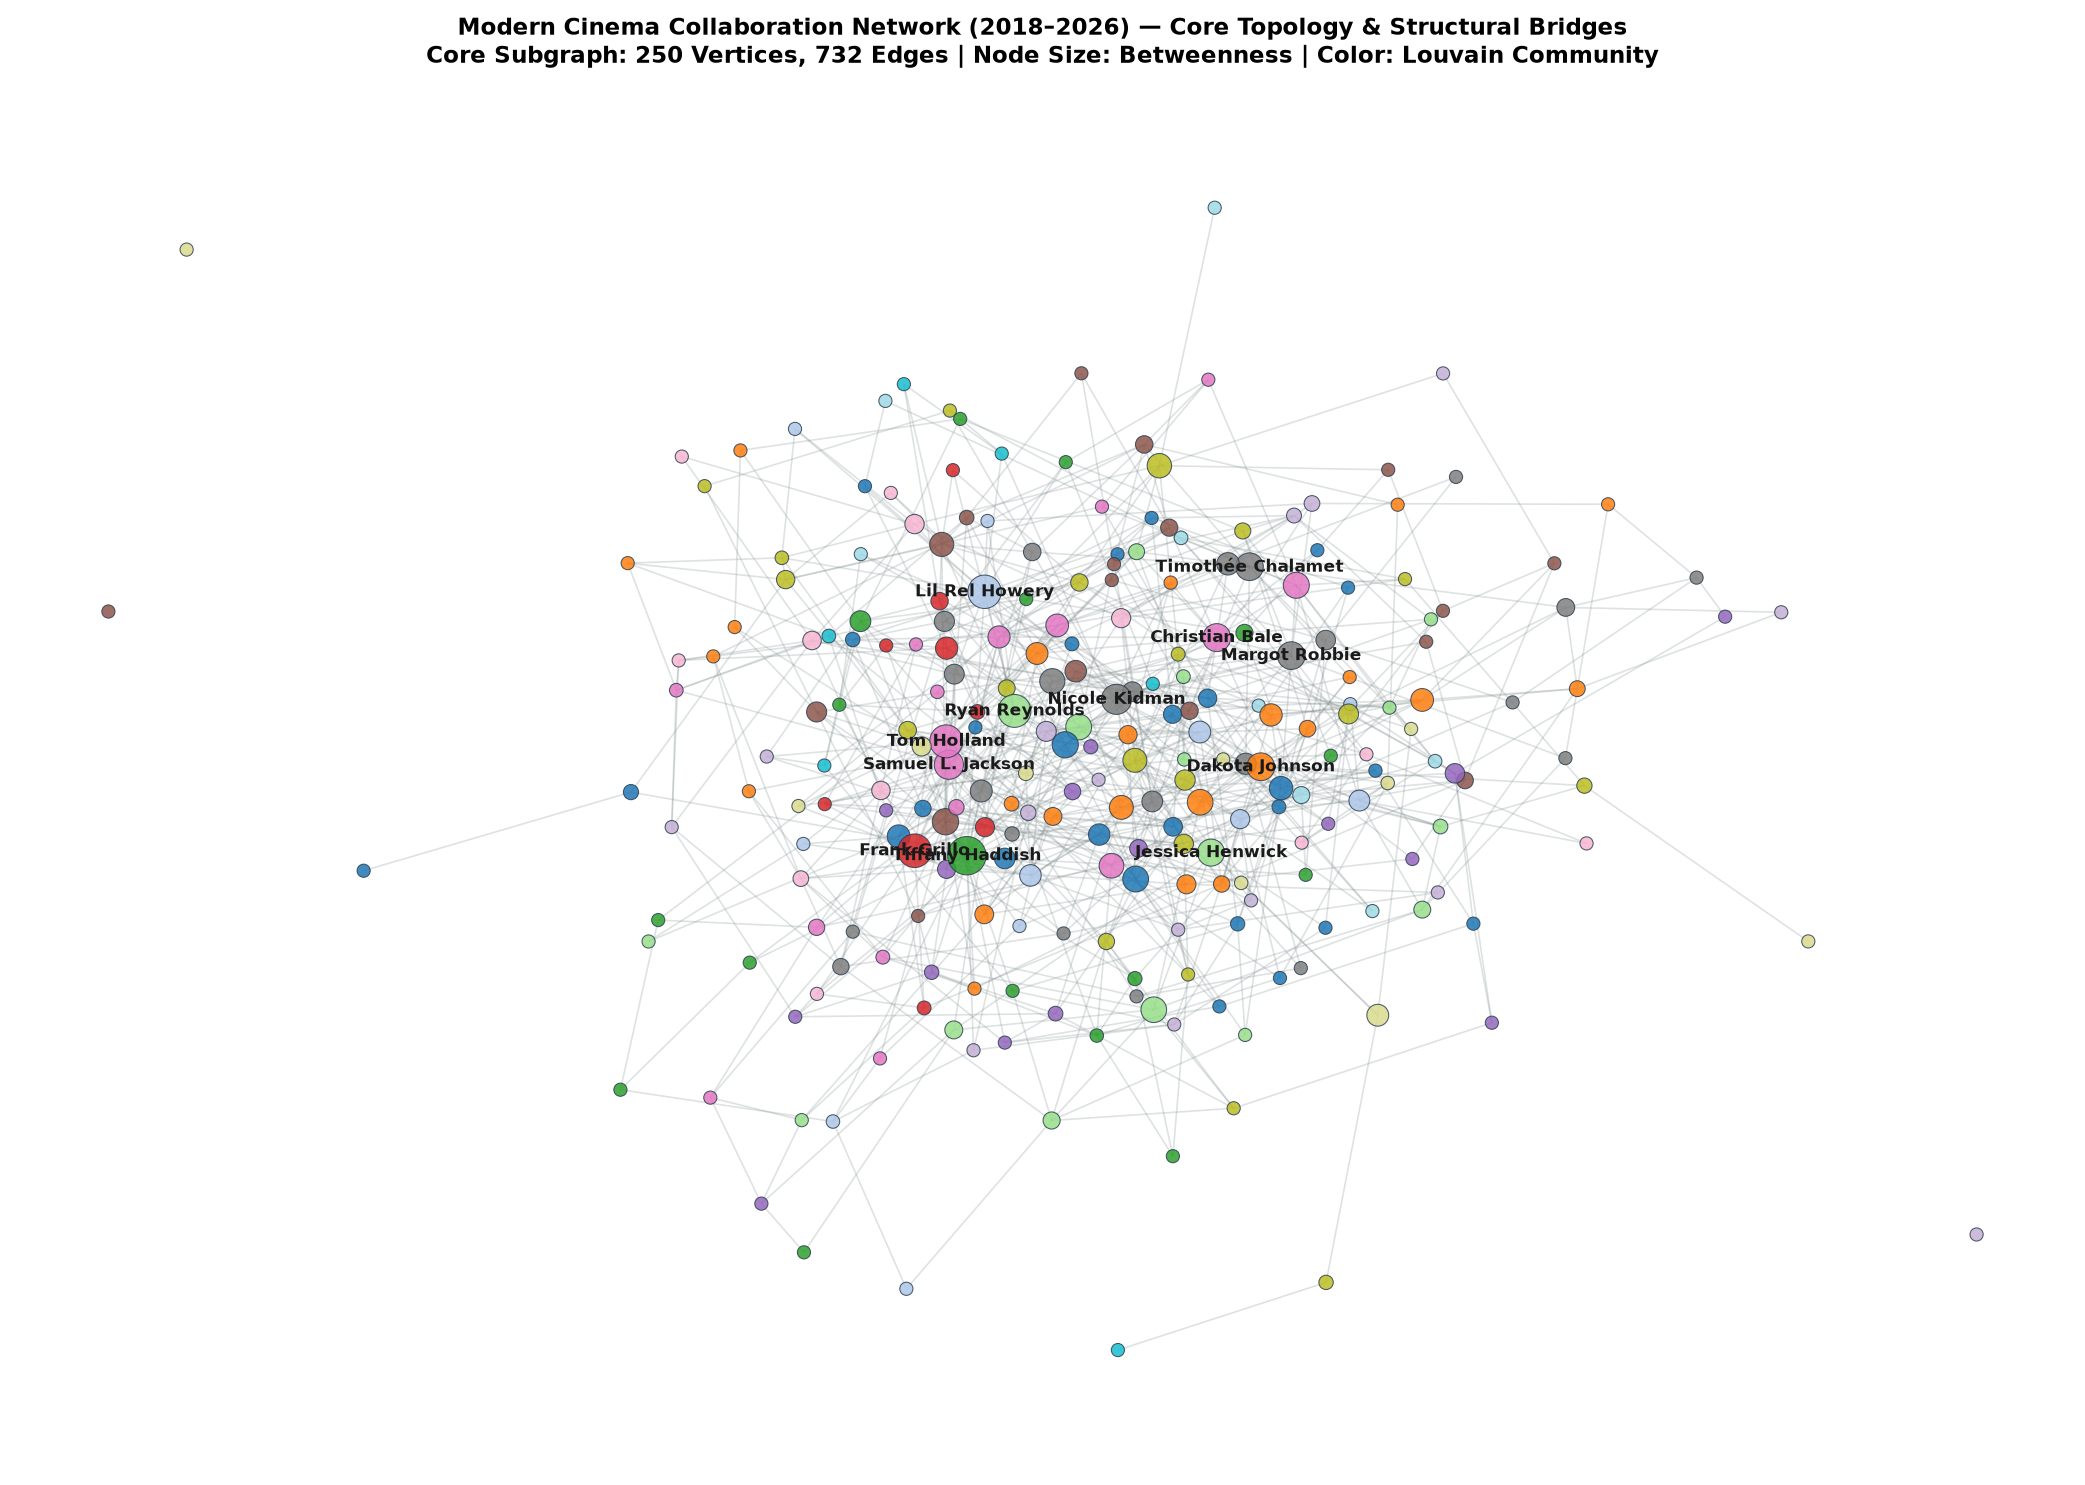

In [8]:
core_nodes = [node for node, deg in sorted(gcc.degree(), key=lambda x: x[1], reverse=True)[:250]]
core_subgraph = gcc.subgraph(core_nodes).copy()

node_to_comm = {}
for comm_id, c in enumerate(comms):
    for node in c:
        node_to_comm[node] = comm_id

core_bc = nx.betweenness_centrality(core_subgraph)
node_sizes = [max(40, core_bc[n] * 6000) for n in core_subgraph.nodes()]
node_colors = [node_to_comm.get(n, 0) % 16 for n in core_subgraph.nodes()]

plt.figure(figsize=(14, 10), dpi=150)
pos = nx.spring_layout(core_subgraph, seed=42, k=0.18, iterations=50)

nx.draw_networkx_edges(core_subgraph, pos, alpha=0.25, edge_color="#7f8c8d", width=0.8)
nx.draw_networkx_nodes(
    core_subgraph, pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    alpha=0.85,
    edgecolors="#2c3e50",
    linewidths=0.5
)

top_labeled = sorted(core_bc.items(), key=lambda x: x[1], reverse=True)[:12]
labels = {n: n for n, _ in top_labeled}
nx.draw_networkx_labels(core_subgraph, pos, labels=labels, font_size=8, font_weight="bold", font_color="#1a1a1a")

plt.title(
    "Modern Cinema Collaboration Network (2018–2026) — Core Topology & Structural Bridges\n"
    f"Core Subgraph: {core_subgraph.number_of_nodes()} Vertices, {core_subgraph.number_of_edges()} Edges | Node Size: Betweenness | Color: Louvain Community",
    fontsize=11, fontweight="bold", pad=12
)
plt.axis("off")
plt.tight_layout()
plt.show()


### 9. Step 3: Visualization 2 — Girvan-Newman Divisive Decomposition
A 2-panel comparative layout showing Community $C_0$ before and after partitioning:
* **Panel A:** Intact community with the 4 critical Girvan-Newman bridge edges highlighted in bold crimson dashed lines.
* **Panel B:** Decoupled network after 36 edge removals, displaying the 5 isolated sub-communities in distinct categorical colors ($Q = 0.6089$).


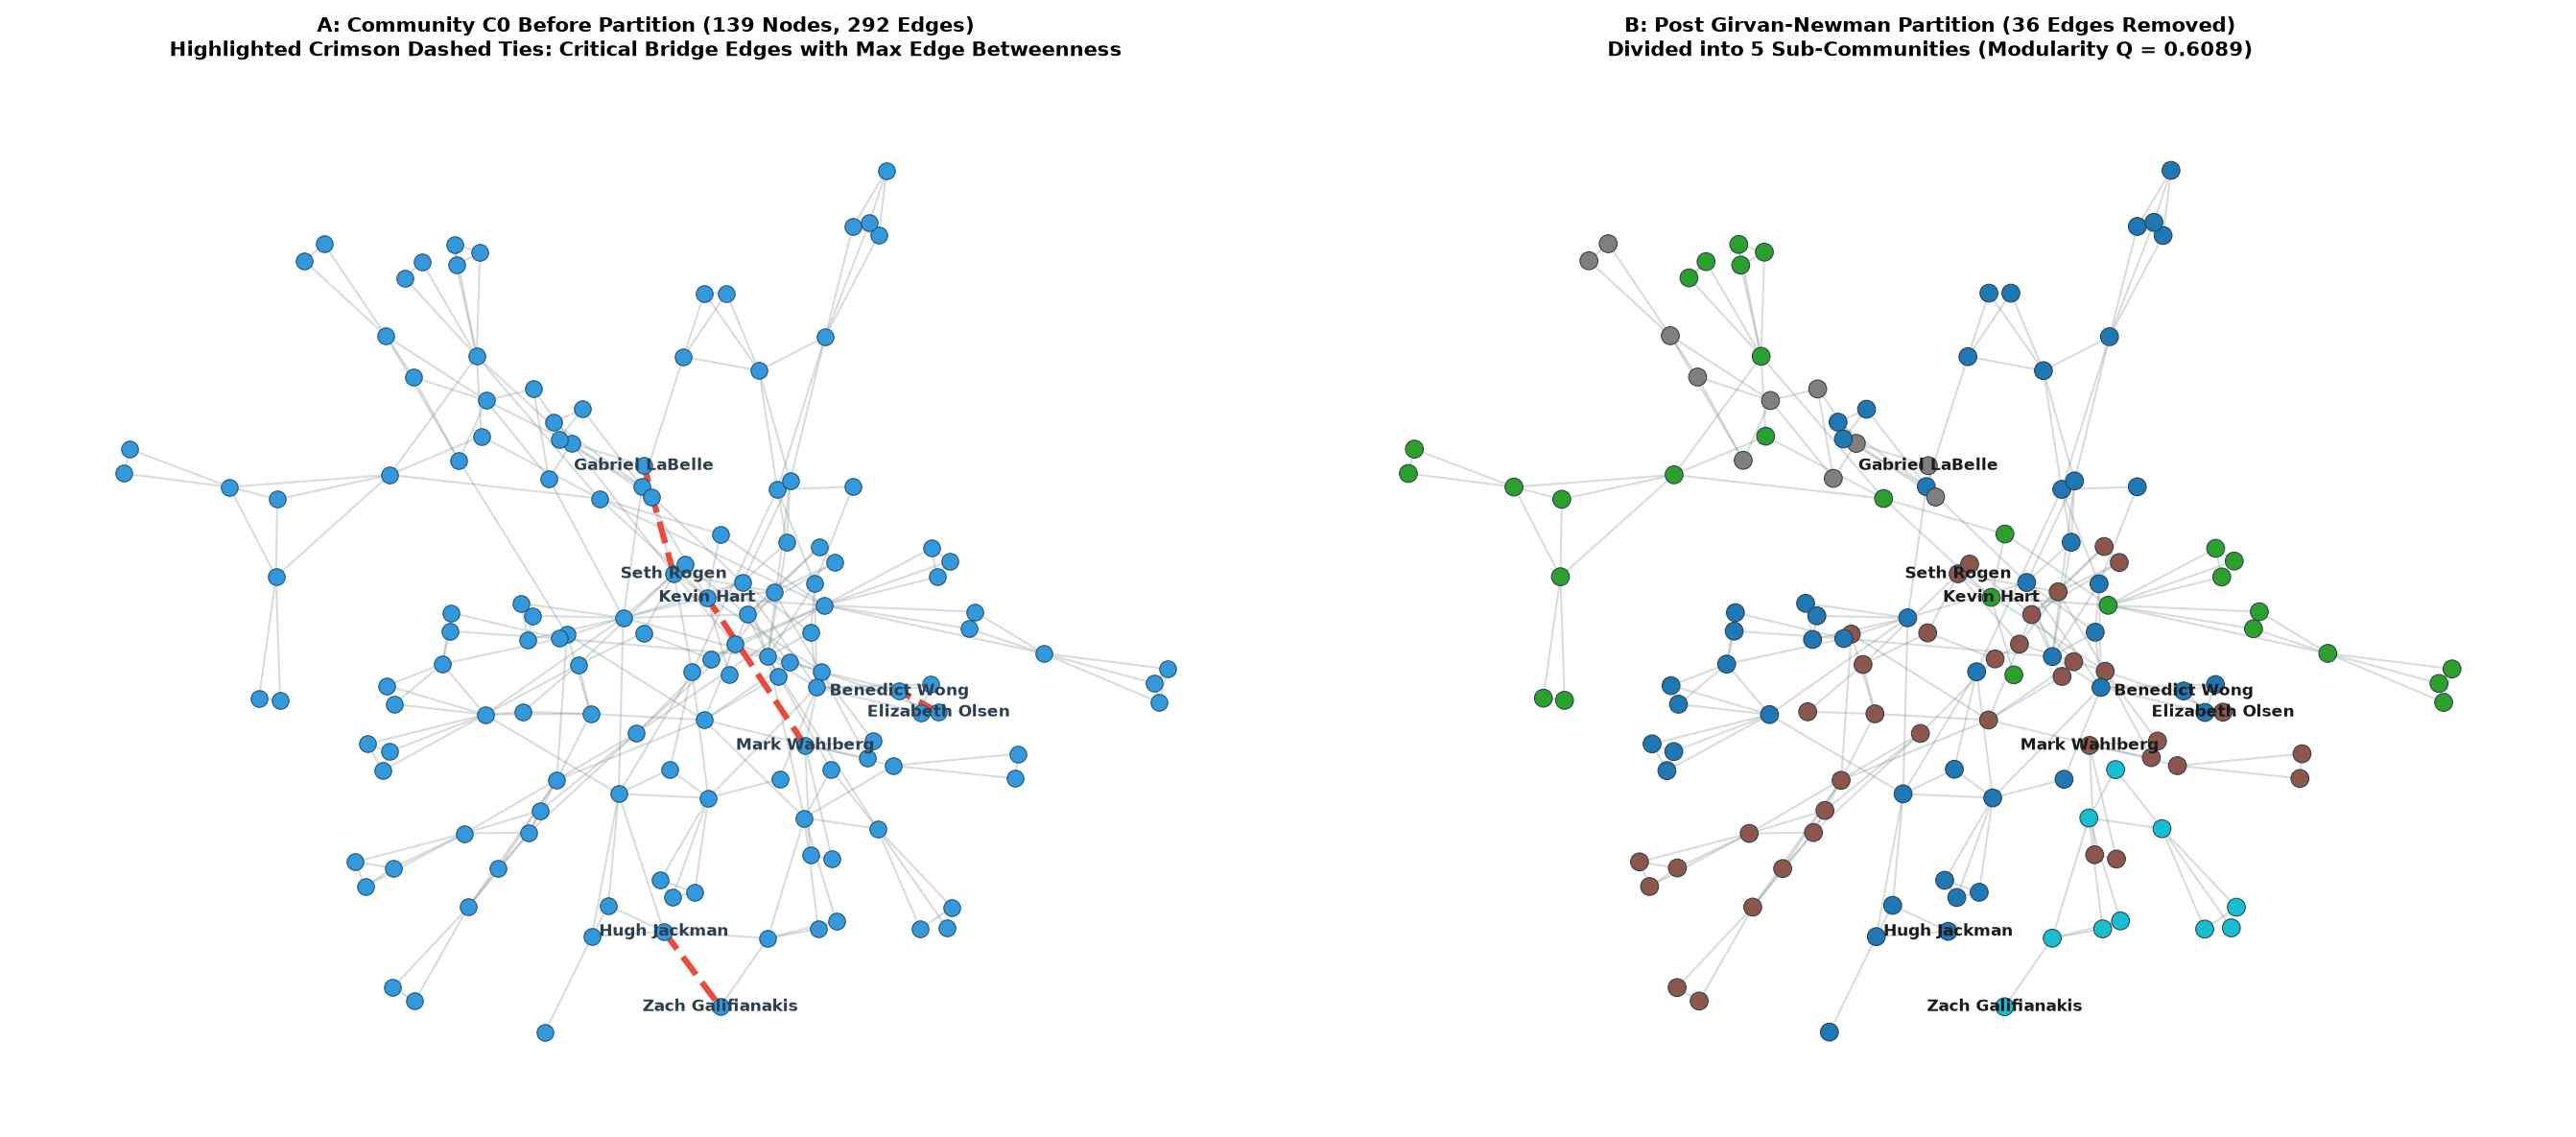

In [9]:
final_comps = list(nx.connected_components(sub))
fig, axes = plt.subplots(1, 2, figsize=(18, 8), dpi=150)
pos_c0 = nx.spring_layout(c0, seed=42, k=0.22, iterations=80)

# Panel A: Before Partitioning
axes[0].set_title(
    "A: Community C0 Before Partition (139 Nodes, 292 Edges)\n"
    "Highlighted Crimson Dashed Ties: Critical Bridge Edges with Max Edge Betweenness",
    fontsize=10, fontweight="bold", pad=12
)
non_crit = [e for e in c0.edges() if tuple(sorted(e)) not in [tuple(sorted(x)) for x in critical_edges]]
nx.draw_networkx_edges(c0, pos_c0, edgelist=non_crit, ax=axes[0], alpha=0.3, edge_color="#7f8c8d", width=1.0)
crit_pres = [e for e in c0.edges() if tuple(sorted(e)) in [tuple(sorted(x)) for x in critical_edges]]
nx.draw_networkx_edges(c0, pos_c0, edgelist=crit_pres, ax=axes[0], edge_color="#e74c3c", width=3.0, style="dashed")
nx.draw_networkx_nodes(c0, pos_c0, ax=axes[0], node_size=70, node_color="#3498db", edgecolors="#1b4f72", linewidths=0.5)

labeled_actors = set()
for u, v in critical_edges:
    labeled_actors.add(u)
    labeled_actors.add(v)
labels_crit = {n: n for n in labeled_actors}
nx.draw_networkx_labels(c0, pos_c0, labels=labels_crit, ax=axes[0], font_size=8, font_weight="bold", font_color="#2c3e50")
axes[0].axis("off")

# Panel B: After Divisive Removal
axes[1].set_title(
    f"B: Post Girvan-Newman Partition (36 Edges Removed)\n"
    f"Divided into 5 Sub-Communities (Modularity Q = 0.6089)",
    fontsize=10, fontweight="bold", pad=12
)
node_comp_map = {}
for cid, comp in enumerate(final_comps):
    for n in comp:
        node_comp_map[n] = cid

colors_sub = [node_comp_map[n] for n in sub.nodes()]
nx.draw_networkx_edges(sub, pos_c0, ax=axes[1], alpha=0.3, edge_color="#7f8c8d", width=1.0)
nx.draw_networkx_nodes(sub, pos_c0, ax=axes[1], node_size=80, node_color=colors_sub, cmap=plt.cm.tab10, edgecolors="#2c3e50", linewidths=0.5)
nx.draw_networkx_labels(sub, pos_c0, labels=labels_crit, ax=axes[1], font_size=8, font_weight="bold", font_color="#1a1a1a")
axes[1].axis("off")

plt.tight_layout()
plt.show()


### 10. Step 3: Visualization 3 — Macro-Topological Distributions
A 3-panel statistical figure examining:
1. Degree distribution histogram with log-log power-law inset ($P(k) \sim k^{-\gamma}$).
2. Granovetter tie strength distribution ($w=1, 2, 3, 4$).
3. Freeman Betweenness vs. Degree Centrality scatter plot highlighting structural bridges.


/var/folders/cd/zdfg1wjj0wjds2knwvlfzddc0000gn/T/ipykernel_3656/4221519977.py:50: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


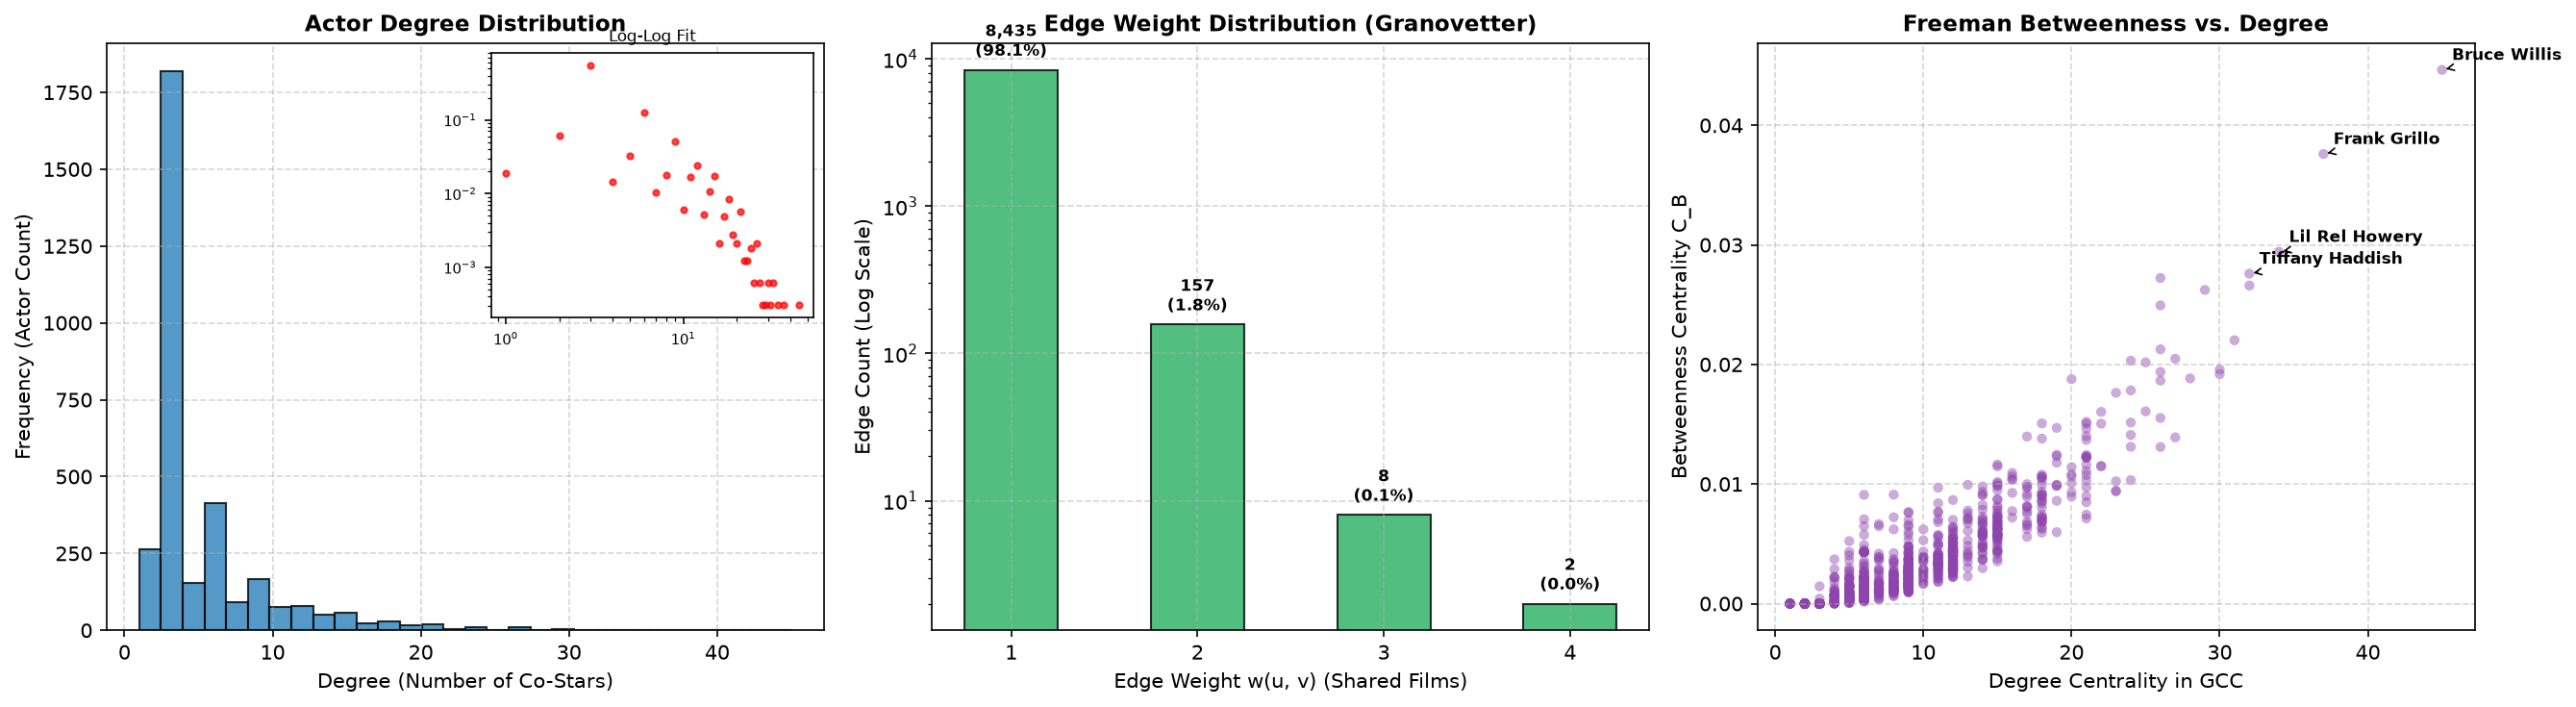

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=150)

# 3A: Degree Distribution
degrees = [d for n, d in G.degree()]
axes[0].hist(degrees, bins=30, color="#2980b9", edgecolor="black", alpha=0.8)
axes[0].set_title("Actor Degree Distribution", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Degree (Number of Co-Stars)", fontsize=10)
axes[0].set_ylabel("Frequency (Actor Count)", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5)

from mpl_toolkits.axes_grid1.inset_locator import inset_axes
ax_inset = inset_axes(axes[0], width="45%", height="45%", loc="upper right")
deg_counts = np.bincount(degrees)
k = np.nonzero(deg_counts)[0]
pk = deg_counts[k] / len(degrees)
ax_inset.loglog(k, pk, "ro", markersize=3, alpha=0.7)
ax_inset.set_title("Log-Log Fit", fontsize=8)
ax_inset.tick_params(labelsize=7)

# 3B: Granovetter Tie Strength
weights = [d["weight"] for u, v, d in G.edges(data=True)]
w_counts = Counter(weights)
w_keys = sorted(w_counts.keys())
w_vals = [w_counts[k] for k in w_keys]
axes[1].bar(w_keys, w_vals, color="#27ae60", edgecolor="black", alpha=0.8, width=0.5)
axes[1].set_yscale("log")
axes[1].set_title("Edge Weight Distribution (Granovetter)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Edge Weight w(u, v) (Shared Films)", fontsize=10)
axes[1].set_ylabel("Edge Count (Log Scale)", fontsize=10)
axes[1].set_xticks(w_keys)
for k_val, v_val in zip(w_keys, w_vals):
    axes[1].text(k_val, v_val * 1.25, f"{v_val:,}\n({v_val/len(weights)*100:.1f}%)", ha="center", fontsize=8, fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3C: Betweenness vs Degree
bc_vals = [bc.get(n, 0) for n in gcc.nodes()]
deg_gcc = [gcc.degree(n) for n in gcc.nodes()]
axes[2].scatter(deg_gcc, bc_vals, alpha=0.45, color="#8e44ad", edgecolors="none", s=25)
axes[2].set_title("Freeman Betweenness vs. Degree", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Degree Centrality in GCC", fontsize=10)
axes[2].set_ylabel("Betweenness Centrality C_B", fontsize=10)
axes[2].grid(True, linestyle="--", alpha=0.5)

top_bridges = sorted(bc.items(), key=lambda x: x[1], reverse=True)[:4]
for name, val in top_bridges:
    d_val = gcc.degree(name)
    axes[2].annotate(name, (d_val, val), textcoords="offset points", xytext=(5, 5),
                     fontsize=8, fontweight="bold", arrowprops=dict(arrowstyle="->", lw=0.8, color="black"))

plt.tight_layout()
plt.show()
